In [1]:
import numpy as np
import xarray as xr
from scipy.signal import savgol_filter
from scipy.interpolate import interp1d

import glob
import os
import warnings
from collections import defaultdict
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import matplotlib.patheffects as pe
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.ticker as mticker
import cmocean
import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D


from swot_analysis import compute_pass_spectra
from swot_analysis import load_swot_l2_expert 


In [48]:
DATA_DIR = '/work/uo0122/u241387/SWOT_SSH/diags_matched/'
ds_months = xr.open_dataset(DATA_DIR+'matched_spectra_2024-12.nc')
ds_months_flag = ds_months.where(ds_months.qc_ok,drop=True)

In [49]:
ds_boxes = xr.open_dataset(DATA_DIR+'matched_boxes_2deg_2024-12.nc')

In [50]:
ds_months.segment.size - ds_months_flag.segment.size

2455

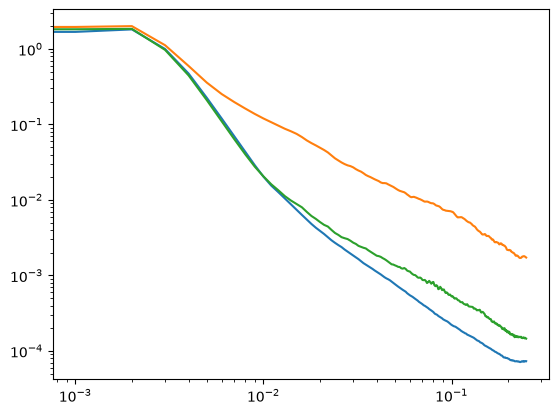

In [51]:
plt.loglog(ds_months.wavenumber,ds_months.expert_psd.mean('segment'))
plt.loglog(ds_months.wavenumber,ds_months.predicted_psd.mean('segment'))
plt.loglog(ds_months_flag.wavenumber,ds_months_flag.predicted_psd.mean('segment'))

In [52]:
ds_months.where(ds_months.qc_ok==False,drop=True)

<xarray.Dataset> Size: 20MB
Dimensions:                        (segment: 2455, wavenumber: 250)
Coordinates:
  * segment                        (segment) int64 20kB 23 24 34 ... 28834 28835
  * wavenumber                     (wavenumber) float64 2kB 0.0 0.001 ... 0.249
Data variables: (12/38)
    predicted_psd                  (segment, wavenumber) float64 5MB 9.628 .....
    direct_psd                     (segment, wavenumber) float64 5MB 8.025 .....
    aliased_psd                    (segment, wavenumber) float64 5MB 1.604 .....
    expert_psd                     (segment, wavenumber) float64 5MB 9.549 .....
    lat_mean                       (segment) float64 20kB 34.63 30.44 ... 7.648
    lon_mean                       (segment) float64 20kB 166.4 167.4 ... 120.2
    ...                             ...
    swath                          (segment) object 20kB 'left' ... 'right'
    segment_index                  (segment) float64 20kB 11.0 12.0 ... 18.0
    cycle                          (segment) float64 20kB 24.0 24.0 ... 26.0
    pass_number                    (segment) float64 20kB 530.0 530.0 ... 228.0
    year                           (segment) float64 20kB 2.024e+03 ... 2.024...
    month                          (segment) float64 20kB 12.0 12.0 ... 12.0
Attributes:
    year:               2024
    month:              12
    ssh_var:            ssha_karin_2
    hret:               0
    segment_length_km:  1000.0
    detrend:            plane

<xarray.DataArray ()> Size: 8B
array(0.0572056)
Coordinates:
    segment  int64 8B 34
Attributes:
    units:    m^2 / (cycles/km)


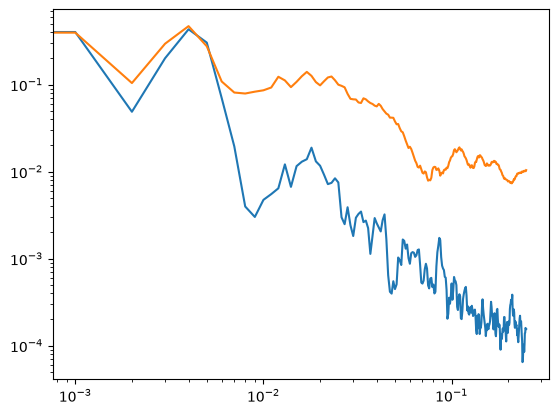

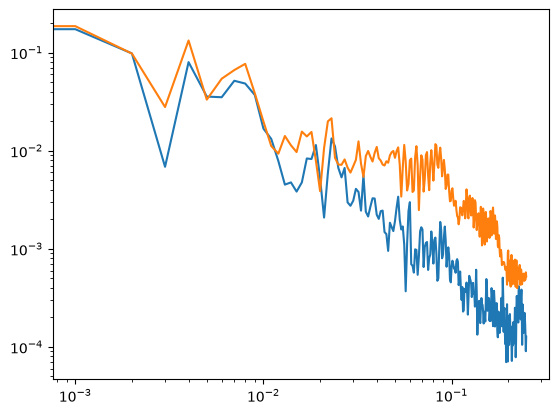

In [58]:
#ds_months.sel(segment=48).expert_psd
plt.loglog(ds_months.wavenumber,ds_months.sel(segment=34).expert_psd)
plt.loglog(ds_months.wavenumber,ds_months.sel(segment=34).predicted_psd)
plt.figure()
plt.loglog(ds_months.wavenumber,ds_months.sel(segment=30).expert_psd)
plt.loglog(ds_months.wavenumber,ds_months.sel(segment=30).predicted_psd)

#plt.loglog(ds_months.wavenumber,ds_months.sel(segment=48).expert_psd/ds_months.sel(segment=48).predicted_psd)
print((ds_months.sel(segment=34).expert_psd/ds_months.sel(segment=34).predicted_psd).sel(wavenumber=slice(1/50,1/10)).mean())


In [54]:
def _hf_ratio(k, predicted, expert, k_min):
    """Mean predicted / mean expert PSD for k >= k_min (NaN if undefined)."""
    m = (k >= k_min) & np.isfinite(predicted) & np.isfinite(expert)
    if m.sum() < 3:
        return np.nan
    e = float(np.mean(expert[m]))
    return float(np.mean(predicted[m]) / e) if e > 0 else np.nan

In [57]:
i = 30
_hf_ratio(ds_months.wavenumber, ds_months.sel(segment=i).predicted_psd, ds_months.sel(segment=i).expert_psd, 1/5)

2.904230084759824

In [18]:
ds_boxes_bis = build_box_dataset(ds_months_flag,min_sampling_fraction=0.15,var='predicted_psd')

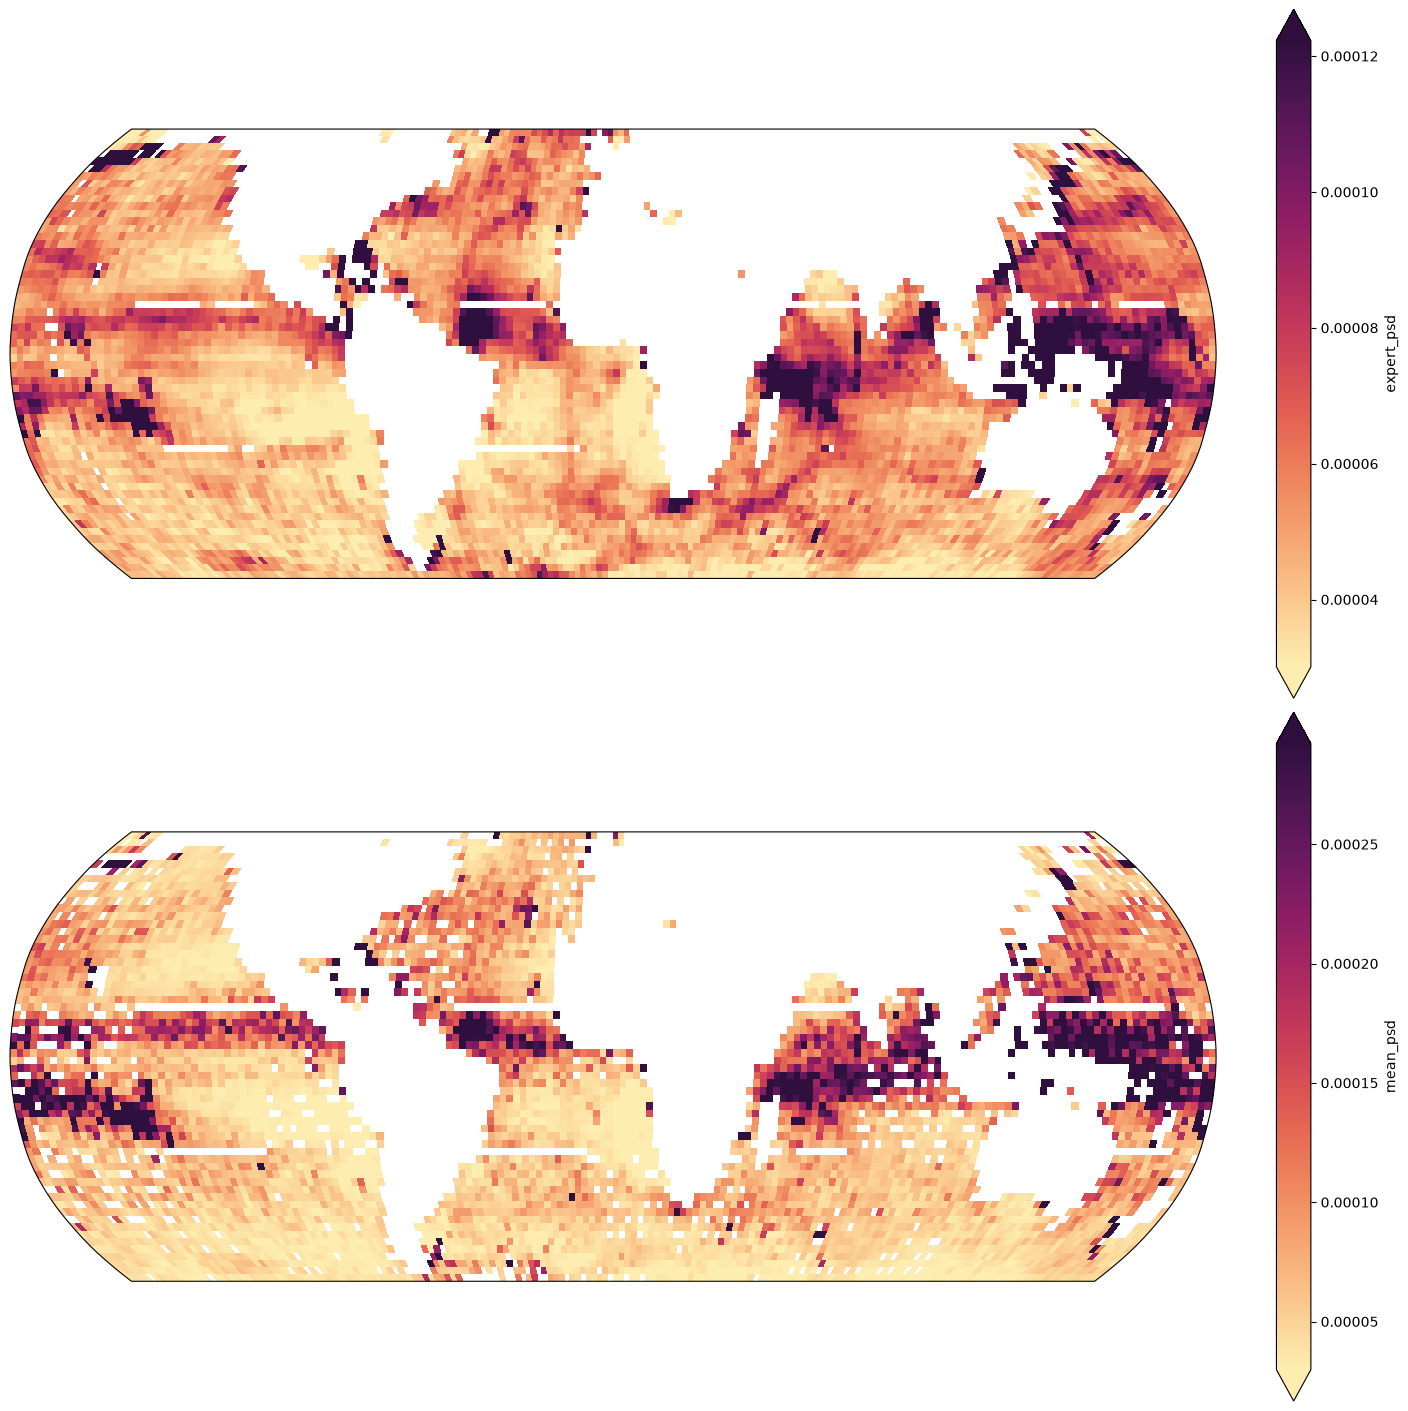

In [19]:
kmin, kmax = 1/50,1/10
energy = ds_boxes.sel(wavenumber=slice(kmin,kmax)).expert_psd.integrate('wavenumber')
energy_pred = ds_boxes_bis.sel(wavenumber=slice(kmin,kmax)).mean_psd.integrate('wavenumber')
fig, axs = plt.subplots(2,1,figsize=(14,14),subplot_kw={"projection": ccrs.Robinson()},constrained_layout=True)
energy.plot(ax=axs[0],transform=ccrs.PlateCarree(),
            vmin=np.nanpercentile(energy,5),
            vmax=np.nanpercentile(energy,95),
           cmap=cmocean.cm.matter)
energy_pred.plot(ax=axs[1],transform=ccrs.PlateCarree(),
            vmin=np.nanpercentile(energy_pred,5),
            vmax=np.nanpercentile(energy_pred,95),
           cmap=cmocean.cm.matter)
axs[0].set_extent([-180,180,-60,60])

In [10]:
def build_box_dataset(ds_segments, box_deg=2.0, method='mean',
                      min_sampling_fraction=0.5, var='psd'):
    """Gridded (lat, lon, wavenumber) box average; lat/lon are box centres."""
    if method not in ('mean', 'median', 'log'):
        raise ValueError(f"method must be 'mean', 'median' or 'log', got {method!r}")
    lat = ds_segments['lat_mean'].values
    lon = ds_segments['lon_mean'].values
    lat_idx = np.floor(lat / box_deg).astype(int)
    lon_idx = np.floor(lon / box_deg).astype(int)
    box_to_segs = defaultdict(list)
    for i, key in enumerate(zip(lat_idx, lon_idx)):
        box_to_segs[key].append(i)

    psd_all = ds_segments[var].values
    wavenumber = ds_segments['wavenumber'].values
    li_axis = np.arange(lat_idx.min(), lat_idx.max() + 1)
    lo_axis = np.arange(lon_idx.min(), lon_idx.max() + 1)
    n_max = max(len(v) for v in box_to_segs.values())
    psd_grid = np.full((li_axis.size, lo_axis.size, wavenumber.size), np.nan)
    n_grid = np.zeros((li_axis.size, lo_axis.size), dtype=int)

    for (li, loi), idxs in box_to_segs.items():
        if len(idxs) < min_sampling_fraction * n_max:
            continue
        sub = psd_all[idxs, :]
        if method == 'mean':
            p = np.nanmean(sub, axis=0)
        elif method == 'median':
            p = np.nanmedian(sub, axis=0)
        else:
            with np.errstate(divide='ignore', invalid='ignore'):
                p = np.exp(np.nanmean(np.log(sub), axis=0))
        psd_grid[li - li_axis[0], loi - lo_axis[0]] = p
        n_grid[li - li_axis[0], loi - lo_axis[0]] = len(idxs)

    return xr.Dataset(
        data_vars=dict(
            mean_psd=(['lat', 'lon', 'wavenumber'], psd_grid,
                      {'long_name': 'Box-mean SSH(A) PSD', 'units': 'm^2 / (cycles/km)'}),
            n_segments=(['lat', 'lon'], n_grid),
            sampling_fraction=(['lat', 'lon'], n_grid / n_max),
        ),
        coords=dict(
            lat=('lat', (li_axis + 0.5) * box_deg, {'units': 'degrees_north'}),
            lon=('lon', (lo_axis + 0.5) * box_deg, {'units': 'degrees_east'}),
            wavenumber=('wavenumber', wavenumber, {'units': 'cycles/km'}),
        ),
        attrs=dict(box_size_deg=box_deg, min_sampling_fraction=min_sampling_fraction),
    )


In [11]:
def plot_box(var: np.array, lon: np.array, lat: np.array,
             box_deg: float = None,
             projection: ccrs = ccrs.Robinson(), cmap: str = "viridis",
             figsize: tuple = (14, 7),
             title: str = "Number of observations per box", label: str = "Number of observations",
             vmin: float = None, vmax: float = None,
             fig = None, ax = None
            ):
    mask = np.isfinite(var)
    lon = lon[mask]
    lat = lat[mask]
    var = var[mask]

    # Infer box size from the spacing of box centers if not given
    if box_deg is None:
        lat_diffs = np.diff(np.unique(np.round(lat, 6)))
        lon_diffs = np.diff(np.unique(np.round(lon, 6)))
        box_deg = np.min(np.concatenate([lat_diffs, lon_diffs]))

    # Reconstruct the regular grid of box centers
    lat_centers = np.arange(lat.min(), lat.max() + box_deg, box_deg)
    lon_centers = np.arange(lon.min(), lon.max() + box_deg, box_deg)

    lat_idx = np.round((lat - lat_centers[0]) / box_deg).astype(int)
    lon_idx = np.round((lon - lon_centers[0]) / box_deg).astype(int)

    grid = np.full((lat_centers.size, lon_centers.size), np.nan)
    grid[lat_idx, lon_idx] = var

    # pcolormesh wants cell edges, not centers
    lat_edges = np.concatenate([lat_centers - box_deg / 2, [lat_centers[-1] + box_deg / 2]])
    lon_edges = np.concatenate([lon_centers - box_deg / 2, [lon_centers[-1] + box_deg / 2]])

    if ax is None:
        fig = plt.figure(figsize=figsize)
        ax = plt.axes(projection=projection)
    ax.set_global()
    ax.add_feature(cfeature.LAND, facecolor="0.9", edgecolor="none")
    ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
    ax.add_feature(cfeature.BORDERS, linewidth=0.3)
    gl = ax.gridlines(draw_labels=True, linewidth=0.3, linestyle="--", alpha=0.5)

    gl.top_labels = False
    gl.right_labels = False
    gl.xlocator = mticker.FixedLocator(np.arange(-180, 181, 60))
    gl.ylocator = mticker.FixedLocator(np.arange(-60, 61, 30))
    gl.xlabel_style = {"size": 10, "color": "black"}
    gl.ylabel_style = {"size": 10, "color": "black"}

    if norm is not None:
        sc = ax.pcolormesh(lon_edges, lat_edges, grid,
                            cmap=cmap, shading='flat',
                            transform=ccrs.PlateCarree(), norm=norm)
    else:
        if vmin is None:
            vmin, vmax = np.nanmin(var), np.nanmax(var)

        sc = ax.pcolormesh(lon_edges, lat_edges, grid,
                            cmap=cmap, shading='flat',
                            transform=ccrs.PlateCarree(), vmin=vmin, vmax=vmax)

    cb = plt.colorbar(sc, ax=ax, shrink=0.6,pad=-0.1,orientation='horizontal')
    cb.set_label(label)
    ax.set_title(title)

    return fig, ax
def estimate_separation_scale_adaptative(psd_all,
                                         wavenumber,
                                         log_k_uniform,
                                         dlogk,
                                         search_mask,
                                         low_k_band: tuple,
                                         high_k_band: tuple,
                                         smooth_window: int = 7,
                                         polyorder: int = 2,
                                         search_range: tuple = None,
                                         n_interp: int = 200,
                                         verbose: bool = False) -> xr.Dataset:
    
    p = psd_all
    valid = np.isfinite(p) & (p > 0)
    if valid.sum() < smooth_window:
        if verbose:
            print('Well well well')
        pass
    k = wavenumber[valid]
    logp = np.log10(p[valid])
    
    # --- Plateau slopes: simple linear fit on RAW (unsmoothed)
    # points within each band, so no window-straddling bias here ---
    low_mask = (k >= low_k_band[0]) & (k <= low_k_band[1])
    high_mask = (k >= high_k_band[0]) & (k <= high_k_band[1])

    if low_mask.sum() < 3 or high_mask.sum() < 3:
        if verbose:
            print(f"Box {i}: not enough points in plateau bands "
                  f"(low={low_mask.sum()}, high={high_mask.sum()}), skipping.")
        pass

    slope_low = np.polyfit(np.log10(k[low_mask]), logp[low_mask], 1)[0]
    slope_high = np.polyfit(np.log10(k[high_mask]), logp[high_mask], 1)[0]
    #slope_low_all[i] = slope_low
    #slope_high_all[i] = slope_high

    # Adaptive threshold: midpoint between the two plateau slopes
    threshold = 0.5 * (slope_low + slope_high)
    #threshold_used[i] = threshold

    # Expect mesoscale (low-k) STEEPER than sub-mesoscale (high-k),
    # i.e. slope_low < slope_high (more negative = steeper).
    if slope_low >= slope_high:
        if verbose:
            print(f"Box {i}: low-k slope ({slope_low:.2f}) not steeper "
                  f"than high-k slope ({slope_high:.2f}) — no clear "
                  f"mesoscale-to-submesoscale steepening-to-shallowing "
                  f"transition, skipping.")
        pass

    
    # --- Local slope curve via SG, same as before ---
    interp_fn = interp1d(np.log10(k), logp, bounds_error=False, fill_value=np.nan)
    logp_uniform = interp_fn(log_k_uniform)
    valid_u = ~np.isnan(logp_uniform)
    if valid_u.sum() < smooth_window:
        if verbose:
            print('Well well well')
        pass

    
    slope_curve = np.full(n_interp, np.nan)
    win = min(smooth_window, valid_u.sum() if valid_u.sum() % 2 == 1 else valid_u.sum() - 1)
    if win <= polyorder:
        if verbose:
            print('Well well well')
        pass
    slope_curve[valid_u] = savgol_filter(logp_uniform[valid_u], window_length=win,
                                              polyorder=polyorder, deriv=1, delta=dlogk)

    mask = search_mask & valid_u
    idxs = np.where(mask)[0]
    if len(idxs) < 2:
        if verbose:
            print(f"Box {i}: fewer than 2 points in search range, skipping.")
        pass

    diff = slope_curve[idxs] - threshold
    sign_change = np.where(np.diff(np.sign(diff)) != 0)[0]
    if len(sign_change) == 0:
        if verbose:
            print(f"Box {i}: slope never crosses adaptive threshold "
                  f"{threshold:.2f}.")
        pass
    try:
        j = sign_change[0]
        frac = -diff[j] / (diff[j + 1] - diff[j])
        i1, i2 = idxs[j], idxs[j + 1]
        log_k_cross = log_k_uniform[i1] + frac * (log_k_uniform[i2] - log_k_uniform[i1])
        separation_k = 10 ** log_k_cross
    except:
        separation_k = np.nan
    return separation_k, threshold,slope_low, slope_high
    
def wrap_separation_scale_adaptive(ds_box: xr.Dataset,
                                        low_k_band: tuple,
                                        high_k_band: tuple,
                                        smooth_window: int = 7,
                                        polyorder: int = 2,
                                        search_range: tuple = None,
                                        n_interp: int = 200,
                                        verbose: bool = False) -> xr.Dataset:
    """
    Non-parametric separation scale using an adaptive (per-box) slope
    threshold, calibrated to each spectrum's own mesoscale (low-k, steep)
    and sub-mesoscale (high-k, shallower) plateau slopes, instead of a
    fixed universal reference slope like -2.

    Physical convention: mesoscale (low-k) is expected to be steeper
    (more negative slope) than sub-mesoscale (high-k), consistent with
    the transition from geostrophic/QG turbulence (~ -5 to -11/3) to a
    shallower sub-mesoscale regime (~ -2 to -5/3).

    Parameters
    ----------
    low_k_band, high_k_band : tuple(float, float)
        Wavenumber ranges (cycles/km) used to estimate the plateau slope
        on each side of the transition, well away from the break itself.
    smooth_window, polyorder : SG smoothing parameters for the local-slope
        curve used to locate the crossing.
    search_range : tuple(float, float), optional
        Restrict the crossing search to this wavenumber range (defaults
        to the union of low_k_band and high_k_band).
    """
    wavenumber = ds_box['wavenumber'].values
    psd_all    = ds_box['mean_psd'].values
    n_boxes    = psd_all.shape[0]

    k_valid = wavenumber > 0
    wavenumber = wavenumber[k_valid]
    psd_all = psd_all[:, k_valid]
    log_k_orig = np.log10(wavenumber)

    if smooth_window % 2 == 0:
        smooth_window += 1

    log_k_uniform = np.linspace(log_k_orig.min(), log_k_orig.max(), n_interp)
    dlogk = log_k_uniform[1] - log_k_uniform[0]

    if search_range is None:
        k_lo = low_k_band[0]
        k_hi = high_k_band[1]
    else:
        k_lo, k_hi = search_range
    search_mask = (10**log_k_uniform >= k_lo) & (10**log_k_uniform <= k_hi)

    separation_k    = np.full(n_boxes, np.nan)
    slope_low_all   = np.full(n_boxes, np.nan)
    slope_high_all  = np.full(n_boxes, np.nan)
    threshold_used  = np.full(n_boxes, np.nan)

    for i in range(n_boxes):
        sep_k, threshold,slope_low, slope_high = estimate_separation_scale_adaptative(psd_all[i],wavenumber,log_k_uniform,dlogk,
                                                                                      search_mask,
                                                                                      low_k_band, high_k_band,
                                                                                     smooth_window = smooth_window,
                                                                                     polyorder=polyorder,
                                                                                     search_range = search_range,
                                                                                     n_interp=n_interp,
                                                                                     verbose=verbose)
        separation_k[i] = sep_k
        threshold_used[i] = threshold
        slope_low_all[i] = slope_low
        slope_high_all[i] = slope_high

    ds_out = ds_box.copy()
    ds_out['separation_wavenumber'] = (
        ['box'], separation_k,
        {'long_name': 'Wavenumber of adaptive-threshold slope crossing '
                       '(mesoscale-to-submesoscale transition)',
         'units': 'cycles/km'}
    )
    ds_out['separation_wavelength'] = (
        ['box'], 1.0 / separation_k,
        {'long_name': 'Separation scale (1/wavenumber)', 'units': 'km'}
    )
    ds_out['slope_low_k'] = (['box'], slope_low_all,
                              {'long_name': 'Fitted mesoscale (low-k) plateau slope'})
    ds_out['slope_high_k'] = (['box'], slope_high_all,
                               {'long_name': 'Fitted sub-mesoscale (high-k) plateau slope'})
    ds_out['adaptive_threshold'] = (['box'], threshold_used,
                                     {'long_name': 'Midpoint slope threshold used per box'})
    return ds_out

<xarray.Dataset> Size: 219MB
Dimensions:                        (segment: 26417, wavenumber: 250)
Coordinates:
  * segment                        (segment) int64 211kB 0 1 2 ... 28870 28871
  * wavenumber                     (wavenumber) float64 2kB 0.0 0.001 ... 0.249
Data variables: (12/38)
    predicted_psd                  (segment, wavenumber) float64 53MB 0.1919 ...
    direct_psd                     (segment, wavenumber) float64 53MB 0.1609 ...
    aliased_psd                    (segment, wavenumber) float64 53MB 0.03098...
    expert_psd                     (segment, wavenumber) float64 53MB 0.1562 ...
    lat_mean                       (segment) float64 211kB -53.04 ... 58.22
    lon_mean                       (segment) float64 211kB 351.6 353.7 ... 305.7
    ...                             ...
    swath                          (segment) object 211kB 'left' ... 'right'
    segment_index                  (segment) float64 211kB 7.0 8.0 ... 28.0 33.0
    cycle                          (segment) float64 211kB 24.0 24.0 ... 26.0
    pass_number                    (segment) float64 211kB 529.0 529.0 ... 229.0
    year                           (segment) float64 211kB 2.024e+03 ... 2.02...
    month                          (segment) float64 211kB 12.0 12.0 ... 12.0
Attributes:
    year:               2024
    month:              12
    ssh_var:            ssha_karin_2
    hret:               0
    segment_length_km:  1000.0
    detrend:            plane

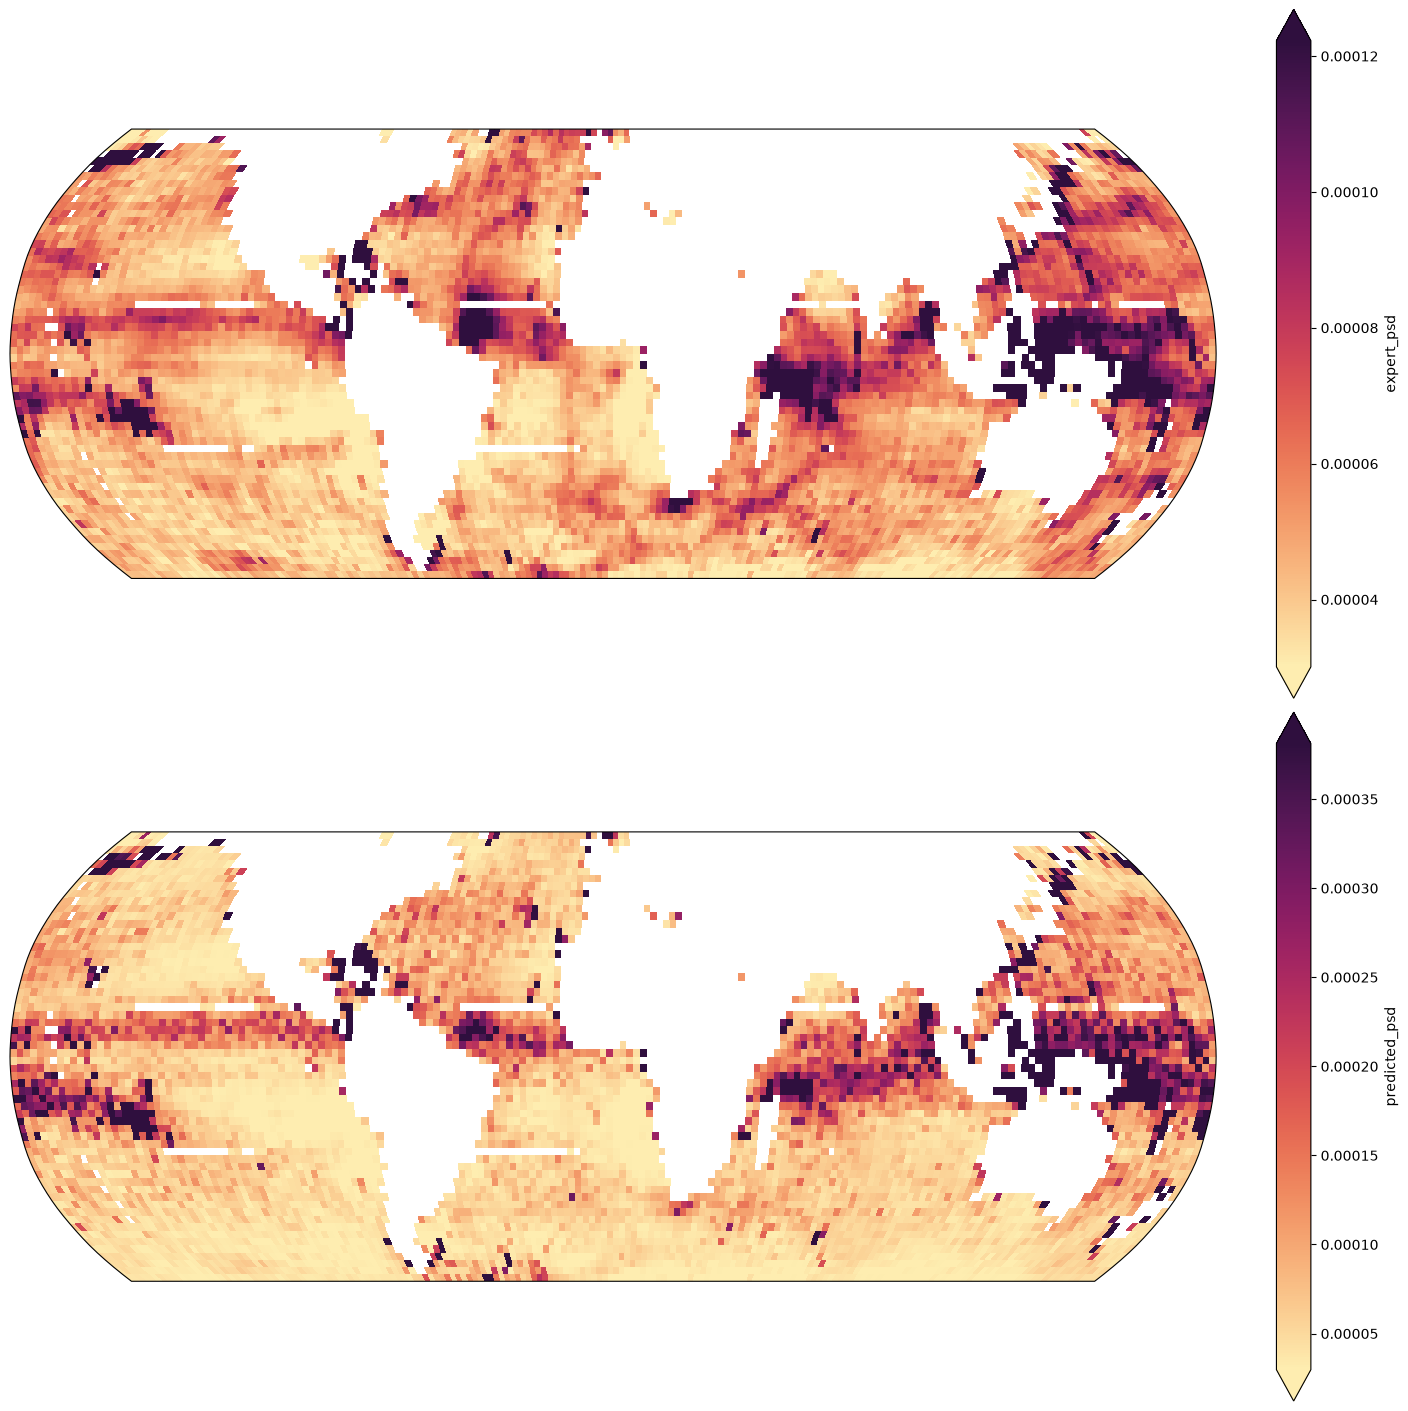

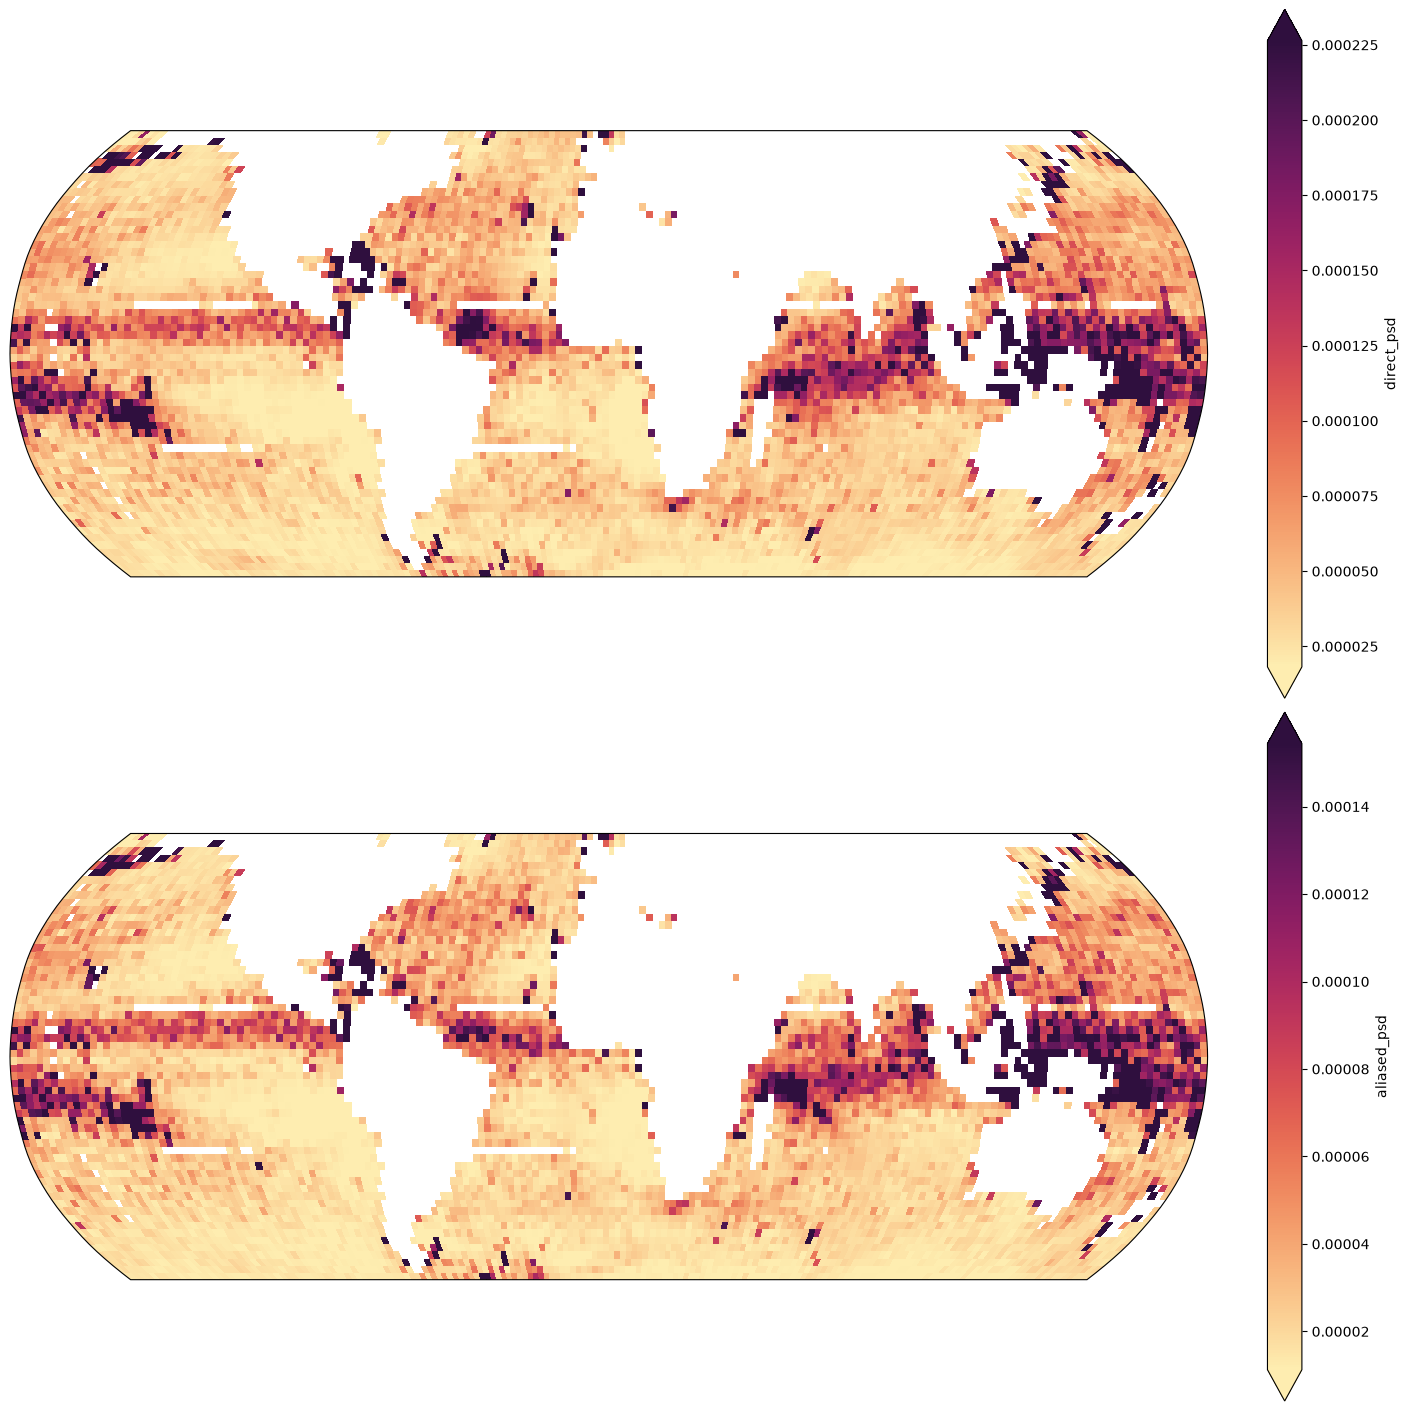

In [12]:
kmin, kmax = 1/50,1/10
energy = ds_boxes.sel(wavenumber=slice(kmin,kmax)).expert_psd.integrate('wavenumber')
energy_pred = ds_boxes.sel(wavenumber=slice(kmin,kmax)).predicted_psd.integrate('wavenumber')
energy_alias = ds_boxes.sel(wavenumber=slice(kmin,kmax)).aliased_psd.integrate('wavenumber')
energy_direct = ds_boxes.sel(wavenumber=slice(kmin,kmax)).direct_psd.integrate('wavenumber')
fig, axs = plt.subplots(2,1,figsize=(14,14),subplot_kw={"projection": ccrs.Robinson()},constrained_layout=True)
energy.plot(ax=axs[0],transform=ccrs.PlateCarree(),
            vmin=np.nanpercentile(energy,5),
            vmax=np.nanpercentile(energy,95),
           cmap=cmocean.cm.matter)
energy_pred.plot(ax=axs[1],transform=ccrs.PlateCarree(),
            vmin=np.nanpercentile(energy_pred,5),
            vmax=np.nanpercentile(energy_pred,95),
           cmap=cmocean.cm.matter)
axs[0].set_extent([-180,180,-60,60])
#ax_.text(-180,70,'(a)',fontsize=14,transform=ccrs.PlateCarree())


fig, axs = plt.subplots(2,1,figsize=(14,14),subplot_kw={"projection": ccrs.Robinson()},constrained_layout=True)
energy_direct.plot(ax=axs[0],transform=ccrs.PlateCarree(),
            vmin=np.nanpercentile(energy_direct,5),
            vmax=np.nanpercentile(energy_direct,95),
           cmap=cmocean.cm.matter)
energy_alias.plot(ax=axs[1],transform=ccrs.PlateCarree(),
            vmin=np.nanpercentile(energy_alias,5),
            vmax=np.nanpercentile(energy_alias,95),
           cmap=cmocean.cm.matter)

In [26]:
from collections import defaultdict

def build_box_dataset(ds_segments, box_deg=2.0, method='mean',
                      min_sampling_fraction=0.5, var='psd'):
    """Gridded (lat, lon, wavenumber) box average; lat/lon are box centres."""
    if method not in ('mean', 'median', 'log'):
        raise ValueError(f"method must be 'mean', 'median' or 'log', got {method!r}")
    lat = ds_segments['lat_mean'].values
    lon = ds_segments['lon_mean'].values
    lat_idx = np.floor(lat / box_deg).astype(int)
    lon_idx = np.floor(lon / box_deg).astype(int)
    box_to_segs = defaultdict(list)
    for i, key in enumerate(zip(lat_idx, lon_idx)):
        box_to_segs[key].append(i)

    psd_all = ds_segments[var].values
    wavenumber = ds_segments['wavenumber'].values
    li_axis = np.arange(lat_idx.min(), lat_idx.max() + 1)
    lo_axis = np.arange(lon_idx.min(), lon_idx.max() + 1)
    n_max = max(len(v) for v in box_to_segs.values())
    psd_grid = np.full((li_axis.size, lo_axis.size, wavenumber.size), np.nan)
    n_grid = np.zeros((li_axis.size, lo_axis.size), dtype=int)

    for (li, loi), idxs in box_to_segs.items():
        if len(idxs) < min_sampling_fraction * n_max:
            continue
        sub = psd_all[idxs, :]
        if method == 'mean':
            p = np.nanmean(sub, axis=0)
        elif method == 'median':
            p = np.nanmedian(sub, axis=0)
        else:
            with np.errstate(divide='ignore', invalid='ignore'):
                p = np.exp(np.nanmean(np.log(sub), axis=0))
        psd_grid[li - li_axis[0], loi - lo_axis[0]] = p
        n_grid[li - li_axis[0], loi - lo_axis[0]] = len(idxs)

    return xr.Dataset(
        data_vars=dict(
            mean_psd=(['lat', 'lon', 'wavenumber'], psd_grid,
                      {'long_name': 'Box-mean SSH(A) PSD', 'units': 'm^2 / (cycles/km)'}),
            n_segments=(['lat', 'lon'], n_grid),
            sampling_fraction=(['lat', 'lon'], n_grid / n_max),
        ),
        coords=dict(
            lat=('lat', (li_axis + 0.5) * box_deg, {'units': 'degrees_north'}),
            lon=('lon', (lo_axis + 0.5) * box_deg, {'units': 'degrees_east'}),
            wavenumber=('wavenumber', wavenumber, {'units': 'cycles/km'}),
        ),
        attrs=dict(box_size_deg=box_deg, min_sampling_fraction=min_sampling_fraction),
    )


def box_all_spectra(ds_segments, **kw):
    """Box-average expert/predicted/direct/aliased PSD of the qc_ok segments."""
    ok = np.where(ds_segments['qc_ok'].values)[0]
    if ok.size == 0:
        raise ValueError('No segment with qc_ok=True.')
    ds_ok = ds_segments.isel(segment=ok).load()
    parts = {v: build_box_dataset(ds_ok, var=v, **kw)
             for v in ('expert_psd', 'predicted_psd', 'direct_psd', 'aliased_psd')}
    out = xr.Dataset({v: p['mean_psd'] for v, p in parts.items()})
    out['n_segments'] = parts['expert_psd']['n_segments']
    out['sampling_fraction'] = parts['expert_psd']['sampling_fraction']
    out.attrs.update(parts['expert_psd'].attrs, n_segments_ok=int(ok.size))
    return out


ds_boxes = {}
for (year, month), f in ds_months.items():
    with xr.open_dataset(f) as ds_m:
        ds_boxes[(year, month)] = box_all_spectra(
            ds_m, box_deg=BOX_DEG, method=BOX_METHOD,
            min_sampling_fraction=MIN_SAMPLING_FRACTION)
    out_file = os.path.join(OUTPUT_DIR, f'matched_boxes_{BOX_DEG:g}deg_{year}-{month:02d}.nc')
    ds_boxes[(year, month)].to_netcdf(out_file, mode='w')
    print(f'{year}-{month:02d}: {int((ds_boxes[(year, month)].n_segments > 0).sum())} boxes -> {out_file}')

ValueError: too many values to unpack (expected 2)